# Mikroskobik görüntülerde klasik yöntemlerle hücre sayımı
**Veri:** Cell Tracking Challenge, Fluo-N2DH-GOWT1 (training arşivi). **Seed:** 31066 (29040 + 2026).

Notebook sırası:
1. Veri inceleme
2. Kare seçimi
3. Referans sayılar (sadece geliştirme ve doğrulama)
4. Baseline
5. Parametre taramaları ve kontrollü deneyler (E01-E22)
6. Aday pipeline'lar ve doğrulama
7. Nihai pipeline
8. Test tahminlerinin kilitlenmesi
9. Test değerlendirmesi ve zamansal analiz

Hücre görüntüsü içeren grafikler `figures_private` klasörüne kaydediliyor ve notebook içine gömülmüyor, çünkü veri seti GitHub'da paylaşılamıyor.

In [1]:
# Kurulum: Colab'da repo klonlanıyor; yerelde repo klasöründen çalıştırın.
import os, sys, platform
REPO_URL = "https://github.com/ibrahimalpsoy/goruntu-isleme-hucre-sayimi.git"
if "google.colab" in sys.modules and not os.path.exists("src"):
    if not os.path.exists("goruntu-isleme-hucre-sayimi"):
        os.system(f"git clone {REPO_URL}")
    os.chdir("goruntu-isleme-hucre-sayimi")
    os.system("pip install -q -r requirements.txt")
sys.path.insert(0, os.path.abspath("."))

# Test değerlendirmesi kilitli tahminler commit edildikten sonra açılıyor (RUN_TEST=1 varsayılan).
RUN_TEST = os.environ.get("RUN_TEST", "1") == "1"

import json, copy, time, subprocess, warnings
import numpy as np, pandas as pd, cv2, matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore", category=FutureWarning)
from src import ayarlar as A
from src.veri import veriyi_hazirla, goruntu_oku, tra_oku, referans_sayi, kare_sayisi
from src.secim import secimi_yap
from src.islemler import (pipeline_calistir, yogunluk_donusumu, filtre_uygula, esikle,
                          morfoloji_uygula, histogram_referansi_ayarla, kucukleri_sil)
from src.deney import metrikler, degerlendir, say, baseline, REFERANS, deney_listesi, ozet_metin

A.klasorleri_hazirla()
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 160, "savefig.bbox": "tight", "font.size": 9})
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30)

def kaydet(fig, ad, veri_gorseli):
    """Hücre görüntüsü içeren grafikler figures_private klasörüne kaydediliyor ve notebook'a
    gömülmüyor (veri seti GitHub'da paylaşılamıyor). Diğer grafikler figures klasörüne kaydedilip gösteriliyor."""
    if veri_gorseli:
        yol = A.OZEL_GRAFIK_KLASORU / ad
        fig.savefig(yol); plt.close(fig)
        print(f"Veri görüntüsü içeren grafik kaydedildi: figures_private/{ad} (sadece raporda kullanılıyor)")
    else:
        fig.savefig(A.GRAFIK_KLASORU / ad); plt.show()

def gorsel(img, ust=99.8):
    """Sadece ekranda göstermek için parlaklık artırma (işleme etkisi yok)."""
    u = max(np.percentile(img, ust), 1)
    return np.clip(img.astype(float) / u, 0, 1)

print("Python", platform.python_version(), "| OpenCV", cv2.__version__, "| numpy", np.__version__)
print("Seed:", A.SEED, "(29040 + 2026)")

Python 3.13.18 | OpenCV 5.0.0 | numpy 2.5.3
Seed: 31066 (29040 + 2026)


## 1. Veri inceleme

In [2]:
veriyi_hazirla()
rows = []
for s in ("01", "02"):
    n = kare_sayisi(s)
    ornek = [goruntu_oku(s, k) for k in range(0, n, 10)]
    hepsi = np.concatenate([o.ravel() for o in ornek])
    rows.append({"sekans": s, "kare_sayisi": n, "boyut": f"{ornek[0].shape[1]}x{ornek[0].shape[0]}",
                 "veri_tipi": str(ornek[0].dtype), "min": int(hepsi.min()), "max": int(hepsi.max()),
                 "ortalama": round(float(hepsi.mean()), 2), "medyan": float(np.median(hepsi)),
                 "yuzdelik_99": float(np.percentile(hepsi, 99)), "sifir_piksel_orani": round(float((hepsi == 0).mean()), 3)})
veri_ozet = pd.DataFrame(rows); veri_ozet.to_csv(A.SONUC_KLASORU / "veri_ozellikleri.csv", index=False)
display(veri_ozet)

,sekans,kare_sayisi,boyut,veri_tipi,min,max,ortalama,medyan,yuzdelik_99,sifir_piksel_orani
0,01,92,1024x1024,uint8,0,255,3.96,0.0,68.0,0.574
1,02,92,1024x1024,uint8,0,155,2.09,0.0,31.0,0.618


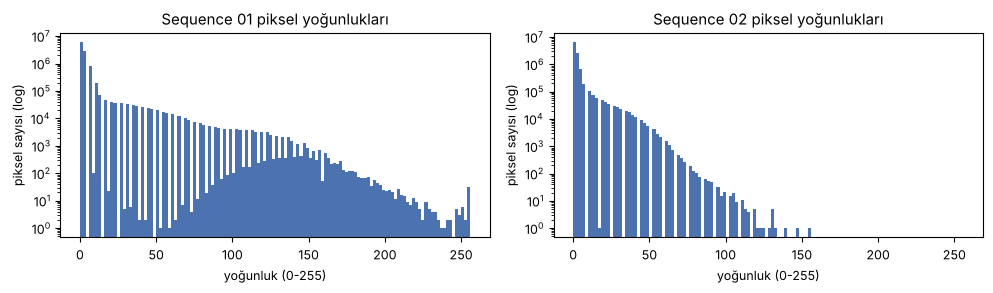

In [3]:
# Piksel yoğunluk histogramları (her 10 karede bir örnek)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for a, s in zip(ax, ("01", "02")):
    hepsi = np.concatenate([goruntu_oku(s, k).ravel() for k in range(0, kare_sayisi(s), 10)])
    a.hist(hepsi, bins=128, range=(0, 256), color="#4c72b0"); a.set_yscale("log")
    a.set_title(f"Sequence {s} piksel yoğunlukları"); a.set_xlabel("yoğunluk (0-255)"); a.set_ylabel("piksel sayısı (log)")
fig.tight_layout(); kaydet(fig, "veri_histogram.png", veri_gorseli=False)

In [4]:
# Örnek kareler (görüntüler sadece rapor için)
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for a, s in zip(ax, ("01", "02")):
    a.imshow(gorsel(goruntu_oku(s, 0)), cmap="gray"); a.set_title(f"Sequence {s}, t000 (görselleştirme için parlaklık artırıldı)"); a.axis("off")
fig.tight_layout(); kaydet(fig, "ornek_kareler.png", veri_gorseli=True)

Veri görüntüsü içeren grafik kaydedildi: figures_private/ornek_kareler.png (sadece raporda kullanılıyor)


## 2. Geliştirme, doğrulama ve test karelerinin seçimi (seed 31066)

In [5]:
secilen, kayit = secimi_yap()
onceki = pd.read_csv("selected_frames.csv", dtype={"sekans": str})
assert onceki[["grup", "sekans", "kare"]].equals(secilen[["grup", "sekans", "kare"]]), "Seçim değişmiş olmamalı!"
print(json.dumps(kayit, indent=1, ensure_ascii=False))
display(secilen)
DEV = secilen.query("grup=='development'")["kare"].tolist()
VAL = secilen.query("grup=='validation'")["kare"].tolist()
TEST = secilen.query("grup=='test'")[["kare", "test_blogu"]].values.tolist()

{
 "seed": 31066,
 "seed_hesabi": "29040 + 2026",
 "sequence01_kare_sayisi": 92,
 "sequence02_kare_sayisi": 92,
 "dev_val_deneme_sayisi": 1,
 "test_deneme_sayisi": 3,
 "development": [
  0,
  2,
  5,
  24,
  27,
  29,
  32,
  59,
  71,
  72
 ],
 "validation": [
  16,
  39,
  51,
  84,
  86
 ],
 "test_blok_baslangiclari": [
  10,
  30,
  64
 ],
 "dev_val_en_kucuk_fark": 7
}


,grup,sekans,kare,test_blogu,dosya_adi,referans_dosyasi,seed
0,development,01,0,-,01/t000.tif,01_GT/TRA/man_track000.tif,31066
1,development,01,2,-,01/t002.tif,01_GT/TRA/man_track002.tif,31066
2,development,01,5,-,01/t005.tif,01_GT/TRA/man_track005.tif,31066
3,development,01,24,-,01/t024.tif,01_GT/TRA/man_track024.tif,31066
4,development,01,27,-,01/t027.tif,01_GT/TRA/man_track027.tif,31066
5,development,01,29,-,01/t029.tif,01_GT/TRA/man_track029.tif,31066
6,development,01,32,-,01/t032.tif,01_GT/TRA/man_track032.tif,31066
7,development,01,59,-,01/t059.tif,01_GT/TRA/man_track059.tif,31066
8,development,01,71,-,01/t071.tif,01_GT/TRA/man_track071.tif,31066
9,development,01,72,-,01/t072.tif,01_GT/TRA/man_track072.tif,31066


## 3. Referans hücre sayıları (geliştirme ve doğrulama)
Referans sayı = `01_GT/TRA/man_trackXXX.tif` görüntüsünde 0 dışındaki farklı hücre kimliklerinin sayısı.
Test karelerinin referanslarına bu aşamada bakılmıyor.

In [6]:
IMG_DEV = {k: goruntu_oku("01", k) for k in DEV}
IMG_VAL = {k: goruntu_oku("01", k) for k in VAL}
REF_DEV = {k: referans_sayi("01", k) for k in DEV}
REF_VAL = {k: referans_sayi("01", k) for k in VAL}
ref_tablo = pd.DataFrame([{"grup": "development", "kare": k, "referans_sayi": REF_DEV[k]} for k in DEV] +
                         [{"grup": "validation", "kare": k, "referans_sayi": REF_VAL[k]} for k in VAL])
ref_tablo.to_csv(A.SONUC_KLASORU / "referans_dev_val.csv", index=False)
display(ref_tablo.pivot_table(index="grup", values="referans_sayi", aggfunc=["min", "max", "mean"]))

,min,max,mean
,referans_sayi,referans_sayi,referans_sayi
grup,,,
development,21,24,22.8
validation,20,24,22.2


,kare,alan,ort_parlaklik,eksantriklik
count,228.00,228.00,228.00,228.00
mean,31.10,1826.14,34.05,0.22
std,25.19,685.27,25.09,0.24
min,0.00,373.00,3.16,0.00
25%,5.00,1418.25,12.26,0.00
50%,27.00,1694.00,27.22,0.19
75%,59.00,1941.00,45.94,0.41
max,72.00,4262.00,108.67,0.87


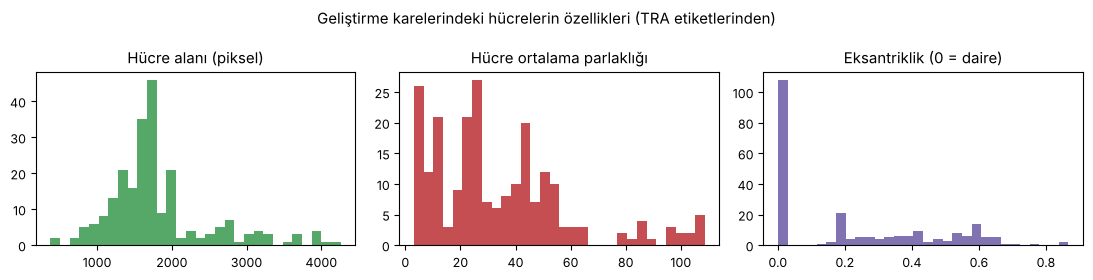

Ortalama parlaklığı 20'nin altında olan (soluk) hücre oranı: %30.7


In [7]:
# Hücre boyutu ve parlaklığı (geliştirme karelerindeki TRA etiketlerinden)
from skimage.measure import regionprops
hucre = []
for k in DEV:
    for r in regionprops(tra_oku("01", k), intensity_image=IMG_DEV[k]):
        hucre.append({"kare": k, "alan": r.area, "ort_parlaklik": r.intensity_mean, "eksantriklik": r.eccentricity})
hucre = pd.DataFrame(hucre); hucre.describe().round(2).to_csv(A.SONUC_KLASORU / "hucre_ozellikleri_dev.csv")
display(hucre.describe().round(2))
fig, ax = plt.subplots(1, 3, figsize=(11, 2.8))
ax[0].hist(hucre.alan, bins=30, color="#55a868"); ax[0].set_title("Hücre alanı (piksel)")
ax[1].hist(hucre.ort_parlaklik, bins=30, color="#c44e52"); ax[1].set_title("Hücre ortalama parlaklığı")
ax[2].hist(hucre.eksantriklik, bins=30, color="#8172b2"); ax[2].set_title("Eksantriklik (0 = daire)")
fig.suptitle("Geliştirme karelerindeki hücrelerin özellikleri (TRA etiketlerinden)"); fig.tight_layout()
kaydet(fig, "hucre_ozellikleri.png", veri_gorseli=False)
print(f"Ortalama parlaklığı 20'nin altında olan (soluk) hücre oranı: %{100 * (hucre.ort_parlaklik < 20).mean():.1f}")

In [8]:
# Görsel kontrol: referans işaretleri ve işaretsiz kalan parlak bölgeler
from skimage.measure import label as sk_label
kontrol = []
fig, axes = plt.subplots(3, 5, figsize=(16, 10))
for a, (g, k) in zip(axes.ravel(), [("dev", k) for k in DEV] + [("val", k) for k in VAL]):
    img, tra = goruntu_oku("01", k), tra_oku("01", k)
    kaba = kucukleri_sil(cv2.GaussianBlur(img, (5, 5), 0) > 6, 200)  # kontrol amaçlı düşük eşik
    lab = sk_label(kaba)
    isaretsiz = [r for r in regionprops(lab) if not (tra[lab == r.label] > 0).any()]
    kenarda = sum(1 for r in isaretsiz if r.bbox[0] == 0 or r.bbox[1] == 0 or r.bbox[2] == 1024 or r.bbox[3] == 1024)
    kontrol.append({"grup": g, "kare": k, "referans": referans_sayi("01", k), "isaretsiz_bolge": len(isaretsiz), "kenara_degen_isaretsiz": kenarda})
    a.imshow(gorsel(img), cmap="gray")
    for r in regionprops(tra): a.plot(r.centroid[1], r.centroid[0], "r+", ms=6)
    for r in isaretsiz: a.add_patch(plt.Rectangle((r.bbox[1], r.bbox[0]), r.bbox[3] - r.bbox[1], r.bbox[2] - r.bbox[0], fill=False, ec="yellow"))
    a.set_title(f"{g} t{k:03d}, referans {referans_sayi('01', k)}"); a.axis("off")
fig.suptitle("Kırmızı +: TRA referans hücreleri, sarı kutu: referansı olmayan parlak bölge"); fig.tight_layout()
kaydet(fig, "referans_kontrol.png", veri_gorseli=True)
kontrol = pd.DataFrame(kontrol); kontrol.to_csv(A.SONUC_KLASORU / "referans_gorsel_kontrol.csv", index=False); display(kontrol)

Veri görüntüsü içeren grafik kaydedildi: figures_private/referans_kontrol.png (sadece raporda kullanılıyor)


,grup,kare,referans,isaretsiz_bolge,kenara_degen_isaretsiz
0,dev,0,23,0,0
1,dev,2,23,0,0
2,dev,5,23,1,0
3,dev,24,24,1,1
4,dev,27,24,1,1
5,dev,29,24,1,1
6,dev,32,24,1,1
7,dev,59,21,1,1
8,dev,71,21,1,1
9,dev,72,21,1,1


## 4. Baseline: gri görüntü + Otsu + bağlı bileşen analizi

In [9]:
# Baseline'ın tek parametresi minimum nesne alanı; geliştirme karelerinde seçilip sabitleniyor.
tarama = []
for ma in [0, 25, 50, 100, 150, 300]:
    m, _, _ = degerlendir(IMG_DEV, REF_DEV, baseline(ma))
    tarama.append({"min_alan": ma, **m})
tarama = pd.DataFrame(tarama); display(tarama.round(3))
BASELINE_MIN_ALAN = int(tarama.sort_values(["MAE", "RMSE"]).iloc[0]["min_alan"])
BASELINE = baseline(BASELINE_MIN_ALAN)
tarama.to_csv(A.SONUC_KLASORU / "baseline_min_alan_taramasi.csv", index=False)
print("Baseline minimum alan:", BASELINE_MIN_ALAN)

k0 = DEV[0]
etiket, n, ara = pipeline_calistir(IMG_DEV[k0], BASELINE, ara_adimlar=True)
fig, ax = plt.subplots(1, 3, figsize=(14, 5))
ax[0].imshow(gorsel(IMG_DEV[k0]), cmap="gray"); ax[0].set_title(f"Orijinal t{k0:03d}")
ax[1].imshow(ara["esikleme"], cmap="gray"); ax[1].set_title("Otsu eşikleme maskesi")
ax[2].imshow(etiket, cmap="nipy_spectral", interpolation="nearest"); ax[2].set_title(f"Bağlı bileşenler (min alan {BASELINE_MIN_ALAN}): {n} nesne, referans {REF_DEV[k0]}")
for a in ax: a.axis("off")
fig.tight_layout(); kaydet(fig, "baseline_ornek.png", veri_gorseli=True)

,min_alan,MAE,RMSE,Bias,Exact_count_acc,Ort_sure_s
0,0,872.4,884.808,872.4,0.0,0.019
1,25,5.8,6.914,0.6,0.1,0.018
2,50,9.1,9.854,-8.3,0.0,0.018
3,100,11.6,12.100,-11.6,0.0,0.018
4,150,12.3,12.550,-12.3,0.0,0.019
5,300,13.2,13.409,-13.2,0.0,0.018


Baseline minimum alan: 25


Veri görüntüsü içeren grafik kaydedildi: figures_private/baseline_ornek.png (sadece raporda kullanılıyor)


## 5. Parametre taramaları ve kontrollü deneyler
İlk denemelerde global Otsu eşiğinin soluk hücreleri kaçırdığını gördüm. Bu yüzden deneylerin başlangıç noktası (E01) olarak
kontrast germe + Gaussian 5x5 + adaptif eşikleme + açma kullandım. Her deneyde bu konfigürasyondan sadece bir adım değişiyor.
Histogram eşleştirmede referans görüntü geliştirme kümesinden seçiliyor (99. yüzdeliği medyana en yakın kare).

Histogram eşleştirme referansı: development t000


,min_mesafe,MAE,RMSE,Bias,Exact_count_acc,Ort_sure_s
0,15,2.8,3.225,2.8,0.0,0.256
1,25,1.9,2.121,1.9,0.0,0.250
2,35,1.1,1.304,1.1,0.2,0.247


En iyi sabit eşik: kontrast germe sonrası T=10, orijinal görüntüde T=3; en iyi minimum alan 400; watershed min mesafe 35


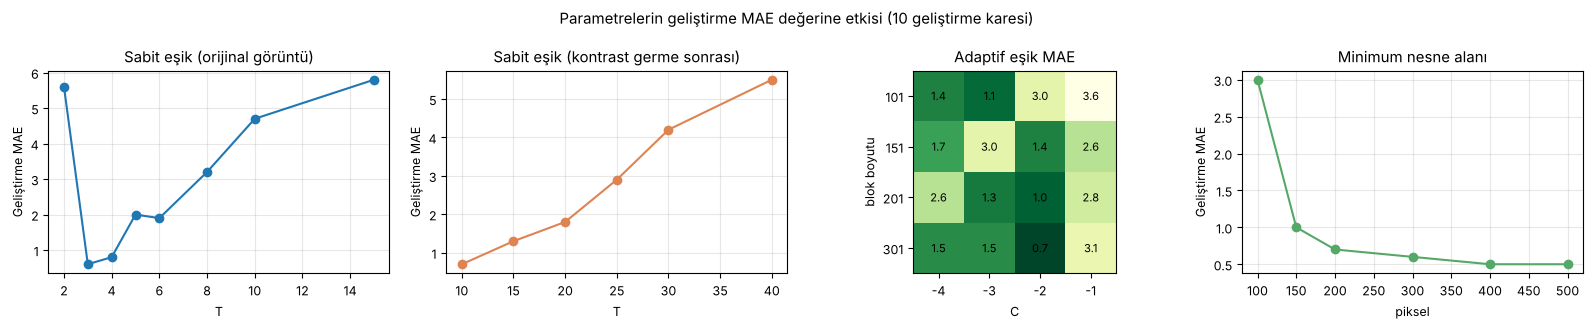

In [10]:
p99 = {k: np.percentile(IMG_DEV[k], 99) for k in DEV}
HM_REF_KARE = min(DEV, key=lambda k: abs(p99[k] - np.median(list(p99.values()))))
histogram_referansi_ayarla(IMG_DEV[HM_REF_KARE]); print("Histogram eşleştirme referansı: development t%03d" % HM_REF_KARE)

def degistir(p, **kw):
    q = copy.deepcopy(p); q.update(copy.deepcopy(kw)); return q

# (a) Sabit eşik T taraması: orijinal görüntü ve kontrast germe sonrası
sabit_orj, sabit_kg = [], []
for T in [2, 3, 4, 5, 6, 8, 10, 15]:
    p = degistir(REFERANS, yogunluk={"yontem": "orijinal"}, esikleme={"yontem": "sabit", "esik": T}, min_alan=300)
    sabit_orj.append({"T": T, **degerlendir(IMG_DEV, REF_DEV, p)[0]})
for T in [10, 15, 20, 25, 30, 40]:
    sabit_kg.append({"T": T, **degerlendir(IMG_DEV, REF_DEV, degistir(REFERANS, esikleme={"yontem": "sabit", "esik": T}))[0]})
sabit_orj, sabit_kg = pd.DataFrame(sabit_orj), pd.DataFrame(sabit_kg)
# (b) Adaptif eşik blok x C
adap = []
for b in [101, 151, 201, 301]:
    for c in [-1, -2, -3, -4]:
        adap.append({"blok": b, "C": c, **degerlendir(IMG_DEV, REF_DEV, degistir(REFERANS, esikleme={"yontem": "adaptif", "blok": b, "C": c, "min_parlaklik": 3}))[0]})
adap = pd.DataFrame(adap)
# (c) Minimum alan
malan = pd.DataFrame([{"min_alan": ma, **degerlendir(IMG_DEV, REF_DEV, degistir(REFERANS, min_alan=ma))[0]} for ma in [100, 150, 200, 300, 400, 500]])
# (d) Watershed minimum tepe mesafesi
wsm = pd.DataFrame([{"min_mesafe": d, **degerlendir(IMG_DEV, REF_DEV, degistir(REFERANS, ayirma={"yontem": "watershed", "min_mesafe": d}))[0]} for d in [15, 25, 35]])
display(wsm.round(3))
tum_tarama = pd.concat([sabit_orj.assign(tarama="sabit_esik_orijinal"), sabit_kg.assign(tarama="sabit_esik_kontrast_germe"),
                        adap.assign(tarama="adaptif_blok_C"), malan.assign(tarama="min_alan"), wsm.assign(tarama="watershed_min_mesafe")], ignore_index=True)
tum_tarama.to_csv(A.SONUC_KLASORU / "parametre_taramalari.csv", index=False)

T_KG = int(sabit_kg.sort_values(["MAE", "RMSE"]).iloc[0]["T"]); T_ORJ = int(sabit_orj.sort_values(["MAE", "RMSE"]).iloc[0]["T"])
MIN_ALAN = int(malan.sort_values(["MAE", "RMSE"]).iloc[0]["min_alan"])
WS_MESAFE = int(wsm.sort_values(["MAE", "RMSE"]).iloc[0]["min_mesafe"])
print(f"En iyi sabit eşik: kontrast germe sonrası T={T_KG}, orijinal görüntüde T={T_ORJ}; en iyi minimum alan {MIN_ALAN}; watershed min mesafe {WS_MESAFE}")

fig, ax = plt.subplots(1, 4, figsize=(16, 3.3))
ax[0].plot(sabit_orj["T"], sabit_orj["MAE"], "o-"); ax[0].set_title("Sabit eşik (orijinal görüntü)"); ax[0].set_xlabel("T")
ax[1].plot(sabit_kg["T"], sabit_kg["MAE"], "o-", color="#dd8452"); ax[1].set_title("Sabit eşik (kontrast germe sonrası)"); ax[1].set_xlabel("T")
pv = adap.pivot(index="blok", columns="C", values="MAE")
im = ax[2].imshow(pv, cmap="YlGn_r"); ax[2].set_xticks(range(len(pv.columns))); ax[2].set_xticklabels(pv.columns)
ax[2].set_yticks(range(len(pv.index))); ax[2].set_yticklabels(pv.index); ax[2].set_xlabel("C"); ax[2].set_ylabel("blok boyutu"); ax[2].set_title("Adaptif eşik MAE")
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]): ax[2].text(j, i, f"{pv.iloc[i, j]:.1f}", ha="center", va="center", color="k", fontsize=8)
ax[3].plot(malan["min_alan"], malan["MAE"], "o-", color="#55a868"); ax[3].set_title("Minimum nesne alanı"); ax[3].set_xlabel("piksel")
for a in (ax[0], ax[1], ax[3]): a.set_ylabel("Geliştirme MAE"); a.grid(alpha=.3)
fig.suptitle("Parametrelerin geliştirme MAE değerine etkisi (10 geliştirme karesi)"); fig.tight_layout()
kaydet(fig, "parametre_taramalari.png", veri_gorseli=False)

,Deney_ID,Grup,Degisiklik,Yogunluk,Filtre,Segmentasyon,Morfoloji,Parametreler,Count_MAE,RMSE,Bias,Ort_sure_s
0,B0,baseline,"Baseline (karşılaştırma için, deney sayısına d...",Orijinal,Yok,Otsu,Yok,min alan 25,5.8,6.91,0.6,0.019
1,E01,referans,Referans konfigürasyon,Kontrast germe,Gauss 5x5,Adaptif b=201 C=-2,açma r3 + delik dold.,min alan 150,1.0,1.18,1.0,0.097
2,E02,yoğunluk,Yoğunluk dönüşümü yok (orijinal),Orijinal,Gauss 5x5,Adaptif b=201 C=-2,açma r3 + delik dold.,min alan 150,1.9,2.02,-0.3,0.080
3,E03,yoğunluk,Histogram eşitleme,Hist. eşitleme,Gauss 5x5,Adaptif b=201 C=-2,açma r3 + delik dold.,min alan 150,28.5,30.43,28.5,0.077
4,E04,yoğunluk,"CLAHE (clip 2.0, 8x8)",CLAHE,Gauss 5x5,Adaptif b=201 C=-2,açma r3 + delik dold.,min alan 150,2.1,2.30,2.1,0.079
5,E05,yoğunluk,Histogram eşleştirme (referans: geliştirme kar...,Hist. eşleştirme,Gauss 5x5,Adaptif b=201 C=-2,açma r3 + delik dold.,min alan 150,1.7,2.07,-1.5,0.081
6,E06,filtre,Filtre yok,Kontrast germe,Yok,Adaptif b=201 C=-2,açma r3 + delik dold.,min alan 150,3.5,3.89,-3.5,0.085
7,E07,filtre,Gaussian 3x3,Kontrast germe,Gauss 3x3,Adaptif b=201 C=-2,açma r3 + delik dold.,min alan 150,3.0,3.13,3.0,0.084
8,E08,filtre,Gaussian 7x7,Kontrast germe,Gauss 7x7,Adaptif b=201 C=-2,açma r3 + delik dold.,min alan 150,2.5,2.81,2.5,0.091
9,E09,filtre,Median 5x5,Kontrast germe,Median 5x5,Adaptif b=201 C=-2,açma r3 + delik dold.,min alan 150,42.6,46.28,42.6,0.084


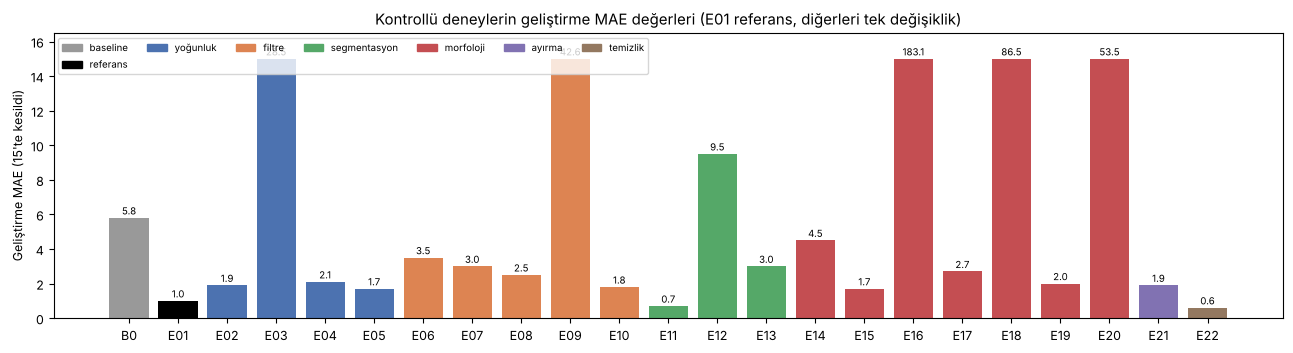

In [11]:
# Kontrollü deneyler (hepsi 10 geliştirme karesinde)
DENEYLER = deney_listesi(T_KG)
rows, deney_sayim = [], {}
for did, grup, aciklama, p in DENEYLER:
    m, sayilar, _ = degerlendir(IMG_DEV, REF_DEV, p)
    y, f, e, mo, par = ozet_metin(p)
    deney_sayim[did] = sayilar
    rows.append({"Deney_ID": did, "Grup": grup, "Degisiklik": aciklama, "Yogunluk": y, "Filtre": f, "Segmentasyon": e,
                 "Morfoloji": mo, "Parametreler": par, "Count_MAE": round(m["MAE"], 2), "RMSE": round(m["RMSE"], 2),
                 "Bias": round(m["Bias"], 2), "Ort_sure_s": round(m["Ort_sure_s"], 3), "Konfigurasyon": json.dumps(p, ensure_ascii=False)})
mb, _, _ = degerlendir(IMG_DEV, REF_DEV, BASELINE); y, f, e, mo, par = ozet_metin(BASELINE)
rows.insert(0, {"Deney_ID": "B0", "Grup": "baseline", "Degisiklik": "Baseline (karşılaştırma için, deney sayısına dahil değil)", "Yogunluk": y, "Filtre": f,
                "Segmentasyon": e, "Morfoloji": mo, "Parametreler": par, "Count_MAE": round(mb["MAE"], 2), "RMSE": round(mb["RMSE"], 2),
                "Bias": round(mb["Bias"], 2), "Ort_sure_s": round(mb["Ort_sure_s"], 3), "Konfigurasyon": json.dumps(BASELINE, ensure_ascii=False)})
deneyler = pd.DataFrame(rows)
deneyler.to_csv("experiments.csv", index=False)
display(deneyler.drop(columns=["Konfigurasyon"]))
fig, ax = plt.subplots(figsize=(13, 3.6))
renk = {"baseline": "#999999", "referans": "k", "yoğunluk": "#4c72b0", "filtre": "#dd8452", "segmentasyon": "#55a868", "morfoloji": "#c44e52", "ayırma": "#8172b2", "temizlik": "#937860"}
ax.bar(deneyler.Deney_ID, deneyler.Count_MAE.clip(upper=15), color=[renk[g] for g in deneyler.Grup])
for i, v in enumerate(deneyler.Count_MAE):
    ax.text(i, min(v, 15) + .2, f"{v:.1f}", ha="center", fontsize=7)
ax.set_ylabel("Geliştirme MAE (15'te kesildi)"); ax.set_ylim(0, 16.5)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in renk.values()], labels=list(renk), ncol=7, fontsize=7, loc="upper left")
ax.set_title("Kontrollü deneylerin geliştirme MAE değerleri (E01 referans, diğerleri tek değişiklik)")
fig.tight_layout(); kaydet(fig, "deney_mae.png", veri_gorseli=False)

In [12]:
# Şekil 2: yoğunluk dönüşümleri ve histogramları (aynı geliştirme karesi)
k = DEV[0]; img = IMG_DEV[k]
donusumler = [("Orijinal", {"yontem": "orijinal"}), ("Kontrast germe (%1-%99.5)", REFERANS["yogunluk"]),
              ("Histogram eşitleme", {"yontem": "hist_esitleme"}), ("CLAHE (clip 2.0, 8x8)", {"yontem": "clahe", "clip": 2.0, "kutu": 8}),
              (f"Histogram eşleştirme (ref. t{HM_REF_KARE:03d})", {"yontem": "hist_eslestirme"})]
fig, ax = plt.subplots(2, 5, figsize=(18, 7), gridspec_kw={"height_ratios": [3, 1.3]})
for j, (ad, ayar) in enumerate(donusumler):
    x = yogunluk_donusumu(img, ayar)
    ax[0, j].imshow(x, cmap="gray", vmin=0, vmax=255); ax[0, j].set_title(ad, fontsize=9); ax[0, j].axis("off")
    ax[1, j].hist(x.ravel(), bins=64, range=(0, 256), color="#4c72b0"); ax[1, j].set_yscale("log"); ax[1, j].set_xlabel("yoğunluk")
fig.suptitle(f"Yoğunluk dönüşümleri ve histogramları, development t{k:03d} (görüntüler dönüşümden sonra 0-255 aralığında gösterildi)")
fig.tight_layout(); kaydet(fig, "sekil2_yogunluk.png", veri_gorseli=True)

Veri görüntüsü içeren grafik kaydedildi: figures_private/sekil2_yogunluk.png (sadece raporda kullanılıyor)


In [13]:
# Filtre karşılaştırması (aynı karenin yakın plan kesiti)
k = DEV[0]; x0 = yogunluk_donusumu(IMG_DEV[k], REFERANS["yogunluk"])
kes = (slice(380, 700), slice(250, 570))
filtreler = [("Filtre yok", {"yontem": "yok"}), ("Gaussian 3x3", {"yontem": "gauss", "kernel": 3}), ("Gaussian 5x5", {"yontem": "gauss", "kernel": 5}),
             ("Gaussian 7x7", {"yontem": "gauss", "kernel": 7}), ("Median 5x5", {"yontem": "median", "kernel": 5}), ("Keskinleştirme", {"yontem": "keskinlestirme", "on_gauss": 5})]
fig, ax = plt.subplots(2, 6, figsize=(20, 7.5))
for j, (ad, ayar) in enumerate(filtreler):
    xf = filtre_uygula(x0, ayar)
    m = morfoloji_uygula(esikle(xf, REFERANS["esikleme"]), REFERANS["morfoloji"])
    ax[0, j].imshow(xf[kes], cmap="gray", vmin=0, vmax=255); ax[0, j].set_title(ad); ax[0, j].axis("off")
    ax[1, j].imshow(m[kes], cmap="gray"); ax[1, j].set_title("adaptif eşik + açma r3"); ax[1, j].axis("off")
fig.suptitle(f"Filtrelerin etkisi, development t{k:03d}, kontrast germe sonrası yakın plan (üst: filtre çıktısı, alt: maske)")
fig.tight_layout(); kaydet(fig, "filtre_karsilastirma.png", veri_gorseli=True)

Veri görüntüsü içeren grafik kaydedildi: figures_private/filtre_karsilastirma.png (sadece raporda kullanılıyor)


In [14]:
# Şekil 3: segmentasyon ve morfoloji karşılaştırması (aynı kesit)
k = DEV[0]; img = IMG_DEV[k]
def mask_of(p):
    et, n, ara = pipeline_calistir(img, p, ara_adimlar=True); return ara, et, n
secenekler = [("E11 sabit T=%d" % T_KG, "E11"), ("E12 Otsu", "E12"), ("E01 adaptif b=201 C=-2", "E01"),
              ("E14 morfoloji yok", "E14"), ("E15 erozyon r3", "E15"), ("E16 genişletme r3", "E16"),
              ("E17 açma r5", "E17"), ("E18 kapama r3", "E18"), ("E19 açma r3 > kapama r3", "E19"), ("E21 + watershed", "E21")]
dmap = {d[0]: d[3] for d in DENEYLER}
fig, ax = plt.subplots(2, 5, figsize=(19, 9.2))
for a, (ad, did) in zip(ax.ravel(), secenekler):
    ara, et, n = mask_of(dmap[did])
    goster = et if did == "E21" else ara["temiz_maske"]
    a.imshow(goster[kes], cmap="nipy_spectral" if did == "E21" else "gray", interpolation="nearest")
    a.set_title(f"{ad}\ntüm karede {n} nesne (referans {REF_DEV[k]})", fontsize=9); a.axis("off")
fig.suptitle(f"Segmentasyon (üst satırın ilk üçü) ve morfolojik işlemlerin karşılaştırması, development t{k:03d} yakın plan", y=1.0)
fig.tight_layout(h_pad=3.0); kaydet(fig, "sekil3_segmentasyon_morfoloji.png", veri_gorseli=True)

Veri görüntüsü içeren grafik kaydedildi: figures_private/sekil3_segmentasyon_morfoloji.png (sadece raporda kullanılıyor)


## 6. Aday pipeline'lar ve doğrulama
Geliştirme sonuçlarından üç tam pipeline oluşturdum:
- **Pipeline A (sabit eşik):** orijinal görüntü, Gaussian 5x5, en iyi sabit eşik, açma r3, delik doldurma, en iyi min alan
- **Pipeline B (adaptif):** kontrast germe, Gaussian 5x5, adaptif eşik (b=201, C=-2), açma r3, delik doldurma, en iyi min alan
- **Pipeline C (adaptif + watershed):** Pipeline B ile aynı, sonuna distance transform + watershed ayrımı ekli

Seçim kuralı: en düşük doğrulama MAE, eşitlikte RMSE, sonra ortalama süre, sonra daha az adım.

In [15]:
PIPELINES = {
    "Pipeline A": degistir(REFERANS, yogunluk={"yontem": "orijinal"}, esikleme={"yontem": "sabit", "esik": T_ORJ}, min_alan=MIN_ALAN),
    "Pipeline B": degistir(REFERANS, min_alan=MIN_ALAN),
    "Pipeline C": degistir(REFERANS, min_alan=MIN_ALAN, ayirma={"yontem": "watershed", "min_mesafe": WS_MESAFE}),
}
KARMASIKLIK = {"Pipeline A": 5, "Pipeline B": 6, "Pipeline C": 7}  # adım sayısı
dev_aday = pd.DataFrame([{"Pipeline": ad, **degerlendir(IMG_DEV, REF_DEV, p)[0]} for ad, p in PIPELINES.items()])
dev_aday.to_csv(A.SONUC_KLASORU / "aday_pipeline_gelistirme.csv", index=False)
print("Geliştirme kümesinde aday pipeline'lar:"); display(dev_aday.round(3))

val_rows, val_sayim = [], {}
for ad, p in list(PIPELINES.items()) + [("Baseline", BASELINE)]:
    m, sayilar, _ = degerlendir(IMG_VAL, REF_VAL, p)
    val_sayim[ad] = sayilar
    y, f, e, mo, par = ozet_metin(p)
    val_rows.append({"Pipeline": ad, "Validation_MAE": round(m["MAE"], 3), "Validation_RMSE": round(m["RMSE"], 3),
                     "Bias": round(m["Bias"], 3), "Ortalama_sure_s": round(m["Ort_sure_s"], 4),
                     "Adim_sayisi": KARMASIKLIK.get(ad, 3), "Aciklama": f"{y} | {f} | {e} | {mo} | {par}"})
val = pd.DataFrame(val_rows)
adaylar = val[val.Pipeline != "Baseline"].sort_values(["Validation_MAE", "Validation_RMSE", "Ortalama_sure_s", "Adim_sayisi"])
SECILEN = adaylar.iloc[0]["Pipeline"]
val["Secim"] = ["Seçildi" if p == SECILEN else ("Referans (aday değil)" if p == "Baseline" else "-") for p in val.Pipeline]
val.to_csv("validation_results.csv", index=False)
display(val)
print("Kare bazında doğrulama sayımları:"); display(pd.DataFrame(val_sayim).assign(Referans=pd.Series(REF_VAL)))
print("Seçilen:", SECILEN)

Geliştirme kümesinde aday pipeline'lar:


,Pipeline,MAE,RMSE,Bias,Exact_count_acc,Ort_sure_s
0,Pipeline A,0.6,0.775,0.0,0.4,0.046
1,Pipeline B,0.5,0.707,0.3,0.5,0.090
2,Pipeline C,0.6,0.775,0.4,0.4,0.245


,Pipeline,Validation_MAE,Validation_RMSE,Bias,Ortalama_sure_s,Adim_sayisi,Aciklama,Secim
0,Pipeline A,1.4,1.732,0.2,0.0458,5,Orijinal | Gauss 5x5 | Sabit T=3 | açma r3 + d...,Seçildi
1,Pipeline B,1.4,2.324,1.4,0.0891,6,Kontrast germe | Gauss 5x5 | Adaptif b=201 C=-...,-
2,Pipeline C,1.6,2.366,1.6,0.2410,7,Kontrast germe | Gauss 5x5 | Adaptif b=201 C=-...,-
3,Baseline,7.0,8.866,0.6,0.0219,3,Orijinal | Yok | Otsu | Yok | min alan 25,Referans (aday değil)


Kare bazında doğrulama sayımları:


,Pipeline A,Pipeline B,Pipeline C,Baseline,Referans
16,23,24,24,9,23
39,22,25,25,24,24
51,22,23,23,21,23
84,23,25,25,27,20
86,22,21,22,33,21


Seçilen: Pipeline A


## 7. Nihai pipeline

In [16]:
FINAL = PIPELINES[SECILEN]
final_json = {
    "secilen_pipeline": SECILEN, "seed": A.SEED, "pipeline": FINAL, "baseline": BASELINE,
    "adim_sirasi": ["yoğunluk dönüşümü", "filtre", "eşikleme", "morfoloji", "delik doldurma", "minimum alan temizliği",
                    "ayırma" if FINAL["ayirma"]["yontem"] != "yok" else "bağlı bileşen etiketleme (8-komşuluk)", "sayım"],
    "secim_gerekcesi": "En düşük doğrulama MAE; eşitlikte RMSE, süre ve adım sayısı.",
    "dogrulama": val.set_index("Pipeline").loc[SECILEN, ["Validation_MAE", "Validation_RMSE", "Ortalama_sure_s"]].to_dict(),
    "parametre_kaynaklari": {"sabit_esik_orijinal": T_ORJ, "sabit_esik_kontrast_germe": T_KG, "min_alan": MIN_ALAN,
                             "baseline_min_alan": BASELINE_MIN_ALAN, "watershed_min_mesafe": WS_MESAFE, "hist_eslestirme_referansi": f"development t{HM_REF_KARE:03d}"},
}
if os.path.exists("final_pipeline.json") and RUN_TEST:
    # kilitlenmiş dosya değiştirilmiyor; sadece aynı pipeline'ın seçildiği kontrol ediliyor
    kilitli_final = json.load(open("final_pipeline.json"))
    print("Kilitli final_pipeline.json ile aynı pipeline mı:",
          kilitli_final["pipeline"] == json.loads(json.dumps(FINAL)) and kilitli_final["baseline"] == json.loads(json.dumps(BASELINE)))
else:
    json.dump(final_json, open("final_pipeline.json", "w"), indent=2, ensure_ascii=False)
print(json.dumps(final_json, indent=1, ensure_ascii=False))

Kilitli final_pipeline.json ile aynı pipeline mı: True
{
 "secilen_pipeline": "Pipeline A",
 "seed": 31066,
 "pipeline": {
  "yogunluk": {
   "yontem": "orijinal"
  },
  "filtre": {
   "yontem": "gauss",
   "kernel": 5
  },
  "esikleme": {
   "yontem": "sabit",
   "esik": 3
  },
  "morfoloji": [
   [
    "acma",
    3
   ]
  ],
  "delik_doldurma": true,
  "min_alan": 400,
  "ayirma": {
   "yontem": "yok"
  }
 },
 "baseline": {
  "yogunluk": {
   "yontem": "orijinal"
  },
  "filtre": {
   "yontem": "yok"
  },
  "esikleme": {
   "yontem": "otsu"
  },
  "morfoloji": [],
  "delik_doldurma": false,
  "min_alan": 25,
  "ayirma": {
   "yontem": "yok"
  }
 },
 "adim_sirasi": [
  "yoğunluk dönüşümü",
  "filtre",
  "eşikleme",
  "morfoloji",
  "delik doldurma",
  "minimum alan temizliği",
  "bağlı bileşen etiketleme (8-komşuluk)",
  "sayım"
 ],
 "secim_gerekcesi": "En düşük doğrulama MAE; eşitlikte RMSE, süre ve adım sayısı.",
 "dogrulama": {
  "Validation_MAE": 1.4,
  "Validation_RMSE": 1.732,


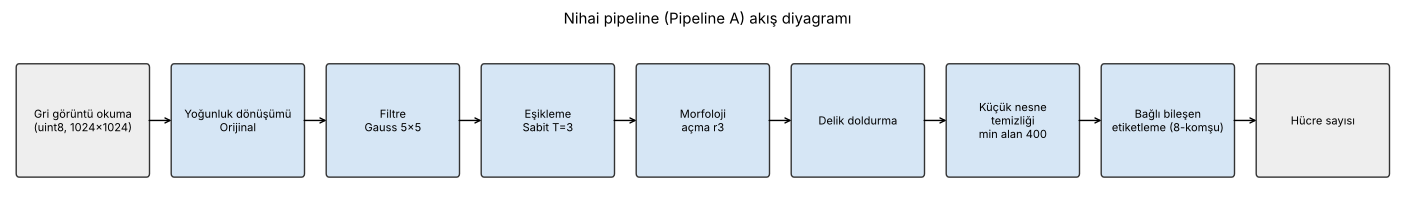

In [17]:
# Şekil 1: nihai pipeline akış diyagramı
from matplotlib.patches import FancyBboxPatch
y, f, e, mo, par = ozet_metin(FINAL)
adimlar = ["Gri görüntü okuma\n(uint8, 1024x1024)", f"Yoğunluk dönüşümü\n{y}", f"Filtre\n{f}", f"Eşikleme\n{e.replace(' C', chr(10) + 'C')}",
           "Morfoloji\n" + ozet_metin(FINAL)[3].split(" +")[0], "Delik doldurma", f"Küçük nesne\ntemizliği\n{par}"]
adimlar.append("Distance transform\n+ watershed" if FINAL["ayirma"]["yontem"] == "watershed" else "Bağlı bileşen\netiketleme (8-komşu)")
adimlar.append("Hücre sayısı")
fig, ax = plt.subplots(figsize=(18, 2.3)); ax.set_xlim(0, len(adimlar)); ax.set_ylim(0, 1); ax.axis("off")
for i, t in enumerate(adimlar):
    ax.add_patch(FancyBboxPatch((i + .06, .2), .82, .6, boxstyle="round,pad=0.02", fc="#d6e6f5" if 0 < i < len(adimlar) - 1 else "#eee", ec="#333"))
    ax.text(i + .47, .5, t, ha="center", va="center", fontsize=8)
    if i: ax.annotate("", (i + .06, .5), (i - .12, .5), arrowprops=dict(arrowstyle="->"))
ax.set_title(f"Nihai pipeline ({SECILEN}) akış diyagramı")
kaydet(fig, "sekil1_akis.png", veri_gorseli=False)

In [18]:
# Şekil 4: nihai pipeline'ın aşama aşama çıktıları (bir doğrulama karesi)
k = VAL[0]
et, n, ara = pipeline_calistir(IMG_VAL[k], FINAL, ara_adimlar=True)
basliklar = [("orijinal", "1. Orijinal (görselleştirme için parlatıldı)"), ("yogunluk", f"2. {ozet_metin(FINAL)[0]}"), ("filtre", f"3. {ozet_metin(FINAL)[1]}"),
             ("esikleme", f"4. {ozet_metin(FINAL)[2]}"), ("morfoloji", "5. " + ozet_metin(FINAL)[3].split(' +')[0]), ("temiz_maske", f"6. Delik doldurma + min alan {FINAL['min_alan']}")]
fig, ax = plt.subplots(2, 4, figsize=(18, 9.5))
for a, (anahtar, b) in zip(ax.ravel(), basliklar):
    v = ara[anahtar]; a.imshow(gorsel(v) if anahtar == "orijinal" else v, cmap="gray"); a.set_title(b, fontsize=9); a.axis("off")
ax[1, 2].imshow(et, cmap="nipy_spectral", interpolation="nearest"); ax[1, 2].set_title(f"7. Etiketler: {n} hücre", fontsize=9); ax[1, 2].axis("off")
ax[1, 3].imshow(gorsel(IMG_VAL[k]), cmap="gray")
from skimage.segmentation import find_boundaries
ax[1, 3].contour(find_boundaries(et), levels=[.5], colors="lime", linewidths=.6)
for r in regionprops(tra_oku("01", k)): ax[1, 3].plot(r.centroid[1], r.centroid[0], "r+", ms=7)
ax[1, 3].set_title(f"8. Sonuç (yeşil) ve referans (kırmızı +): {n} / {REF_VAL[k]}", fontsize=9); ax[1, 3].axis("off")
fig.suptitle(f"Nihai pipeline aşamaları, validation t{k:03d}", y=1.0); fig.tight_layout(h_pad=3.0)
kaydet(fig, "sekil4_asamalar.png", veri_gorseli=True)

# Tüm geliştirme karelerinin görsel kontrolü (ek)
fig, axes = plt.subplots(2, 5, figsize=(20, 8.5))
for a, k in zip(axes.ravel(), DEV):
    et, n = pipeline_calistir(IMG_DEV[k], FINAL)
    a.imshow(gorsel(IMG_DEV[k]), cmap="gray"); a.contour(find_boundaries(et), levels=[.5], colors="lime", linewidths=.5)
    for r in regionprops(tra_oku("01", k)): a.plot(r.centroid[1], r.centroid[0], "r+", ms=5)
    a.set_title(f"dev t{k:03d}: tahmin {n}, referans {REF_DEV[k]}"); a.axis("off")
fig.suptitle("Nihai pipeline, bütün geliştirme kareleri (yeşil: bulunan hücre sınırı, kırmızı +: referans)"); fig.tight_layout()
kaydet(fig, "ek_gelistirme_kareleri.png", veri_gorseli=True)

Veri görüntüsü içeren grafik kaydedildi: figures_private/sekil4_asamalar.png (sadece raporda kullanılıyor)


Veri görüntüsü içeren grafik kaydedildi: figures_private/ek_gelistirme_kareleri.png (sadece raporda kullanılıyor)


## 8. Test tahminlerinin kilitlenmesi
Sabitlenmiş nihai pipeline ve baseline, 15 test karesinde çalıştırılıyor. Bu hücrede test referanslarına (02_GT) **bakılmıyor**.
Tahmin dosyası ve final_pipeline.json ayrı bir commit ile GitHub'a gönderildikten sonra test değerlendirmesi yapılıyor.

In [19]:
kilit = []
for k, blok in TEST:
    img = goruntu_oku("02", k)
    b_say, b_sure = (lambda t0: (pipeline_calistir(img, BASELINE)[1], time.perf_counter() - t0))(time.perf_counter())
    f_say, f_sure = (lambda t0: (pipeline_calistir(img, FINAL)[1], time.perf_counter() - t0))(time.perf_counter())
    kilit.append({"sekans": "02", "kare": k, "test_blogu": blok, "baseline_tahmin": b_say, "nihai_tahmin": f_say,
                  "baseline_sure_s": round(b_sure, 4), "nihai_sure_s": round(f_sure, 4)})
kilit = pd.DataFrame(kilit)
kilit_yolu = "test_predictions_locked.csv"
if RUN_TEST and os.path.exists(kilit_yolu):
    # kilitli dosya zaten varsa üzerine yazılmıyor, sadece aynı tahminlerin üretildiği kontrol ediliyor
    onceki = pd.read_csv(kilit_yolu, dtype={"sekans": str})
    ayni = onceki[["kare", "baseline_tahmin", "nihai_tahmin"]].equals(kilit[["kare", "baseline_tahmin", "nihai_tahmin"]])
    print("Kilitli tahminler yeniden üretildi, commit edilen dosyayla aynı mı:", ayni)
else:
    kilit.to_csv(kilit_yolu, index=False)
    print("Test tahminleri kilitlendi:", kilit_yolu)
display(kilit)

Kilitli tahminler yeniden üretildi, commit edilen dosyayla aynı mı: True


,sekans,kare,test_blogu,baseline_tahmin,nihai_tahmin,baseline_sure_s,nihai_sure_s
0,02,10,B1,29,22,0.0378,0.0440
1,02,11,B1,29,21,0.0201,0.0437
2,02,12,B1,28,21,0.0182,0.0417
3,02,13,B1,29,22,0.0191,0.0415
4,02,14,B1,29,21,0.0185,0.0439
5,02,30,B2,14,21,0.0204,0.0472
6,02,31,B2,20,21,0.0190,0.0422
7,02,32,B2,17,21,0.0192,0.0482
8,02,33,B2,17,21,0.0203,0.0428
9,02,34,B2,18,22,0.0197,0.0427


## 9. Test değerlendirmesi ve zamansal analiz (kilit commit'inden sonra)

In [20]:
def git(*a):
    try: return subprocess.run(["git", *a], capture_output=True, text=True, check=True).stdout.strip()
    except Exception as e: return ""
kilit_commit = git("log", "-1", "--format=%h %ad", "--date=format:%Y-%m-%d %H:%M", "--", "test_predictions_locked.csv")
print("Kilit commit:", kilit_commit or "(bulunamadı)")
if not RUN_TEST:
    print("RUN_TEST=0: test değerlendirmesi bu çalıştırmada yapılmadı.")

Kilit commit: d6da112 2026-11-22 21:13


In [21]:
if RUN_TEST:
    kilitli = pd.read_csv("test_predictions_locked.csv", dtype={"sekans": str})
    kilitli["gercek_sayi"] = [referans_sayi("02", k) for k in kilitli.kare]   # test referansları ilk kez burada okunuyor
    kilitli["baseline_mutlak_hata"] = (kilitli.baseline_tahmin - kilitli.gercek_sayi).abs()
    kilitli["nihai_mutlak_hata"] = (kilitli.nihai_tahmin - kilitli.gercek_sayi).abs()
    test_sonuc = kilitli[["sekans", "kare", "test_blogu", "gercek_sayi", "baseline_tahmin", "nihai_tahmin",
                          "baseline_mutlak_hata", "nihai_mutlak_hata", "baseline_sure_s", "nihai_sure_s"]]
    test_sonuc.to_csv("test_results.csv", index=False)
    display(test_sonuc)
    ozet = pd.DataFrame([
        {"Yontem": "Baseline", **metrikler(test_sonuc.baseline_tahmin, test_sonuc.gercek_sayi, test_sonuc.baseline_sure_s)},
        {"Yontem": "Nihai pipeline", **metrikler(test_sonuc.nihai_tahmin, test_sonuc.gercek_sayi, test_sonuc.nihai_sure_s)}])
    ozet.to_csv(A.SONUC_KLASORU / "test_ozet_metrikler.csv", index=False)
    display(ozet.round(3))
    # doğrulama ile test karşılaştırması
    vt = pd.DataFrame({"Kume": ["Doğrulama (seq 01)", "Test (seq 02)"],
                       "Nihai_MAE": [val.set_index("Pipeline").loc[SECILEN, "Validation_MAE"], ozet.iloc[1]["MAE"]],
                       "Nihai_RMSE": [val.set_index("Pipeline").loc[SECILEN, "Validation_RMSE"], ozet.iloc[1]["RMSE"]],
                       "Baseline_MAE": [val.set_index("Pipeline").loc["Baseline", "Validation_MAE"], ozet.iloc[0]["MAE"]]})
    vt.to_csv(A.SONUC_KLASORU / "dogrulama_test_karsilastirma.csv", index=False); display(vt.round(3))

,sekans,kare,test_blogu,gercek_sayi,baseline_tahmin,nihai_tahmin,baseline_mutlak_hata,nihai_mutlak_hata,baseline_sure_s,nihai_sure_s
0,02,10,B1,24,29,22,5,2,0.0245,0.0439
1,02,11,B1,23,29,21,6,2,0.0188,0.0476
2,02,12,B1,23,28,21,5,2,0.0190,0.0444
3,02,13,B1,22,29,22,7,0,0.0187,0.0483
4,02,14,B1,22,29,21,7,1,0.0192,0.0458
5,02,30,B2,25,14,21,11,4,0.0207,0.0453
6,02,31,B2,25,20,21,5,4,0.0197,0.0471
7,02,32,B2,25,17,21,8,4,0.0193,0.0441
8,02,33,B2,25,17,21,8,4,0.0184,0.0439
9,02,34,B2,25,18,22,7,3,0.0256,0.0512


,Yontem,MAE,RMSE,Bias,Exact_count_acc,Ort_sure_s
0,Baseline,5.6,6.121,-1.2,0.000,0.020
1,Nihai pipeline,3.0,3.276,-3.0,0.067,0.046


,Kume,Nihai_MAE,Nihai_RMSE,Baseline_MAE
0,Doğrulama (seq 01),1.4,1.732,7.0
1,Test (seq 02),3.0,3.276,5.6


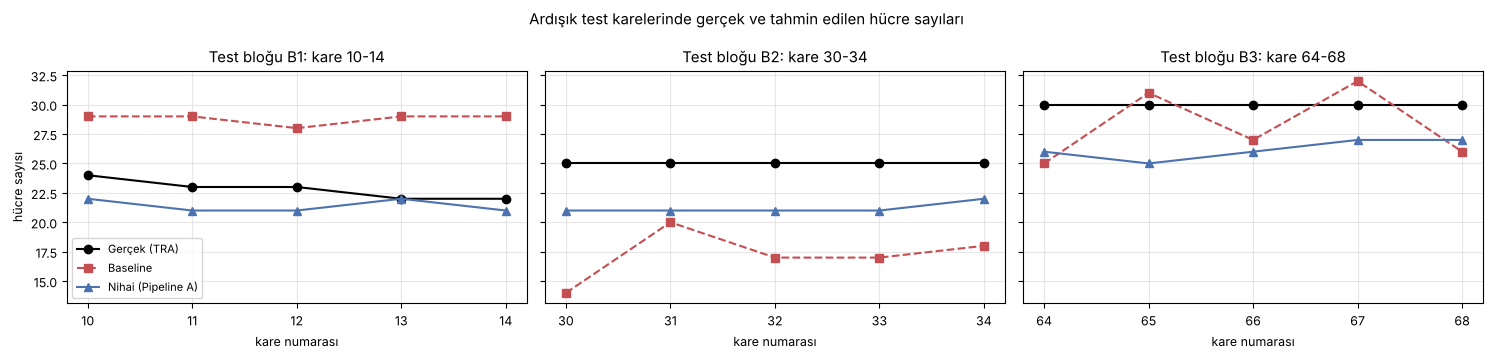

,gercek_toplam_degisim,baseline_toplam_degisim,nihai_toplam_degisim
test_blogu,,,
B1,2,2,3
B2,0,10,1
B3,0,21,3


In [22]:
if RUN_TEST:
    # Şekil 5: üç test bloğunda zamansal hücre sayısı
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
    for a, (blok, g) in zip(ax, test_sonuc.groupby("test_blogu")):
        a.plot(g.kare, g.gercek_sayi, "ko-", label="Gerçek (TRA)")
        a.plot(g.kare, g.baseline_tahmin, "s--", color="#c44e52", label="Baseline")
        a.plot(g.kare, g.nihai_tahmin, "^-", color="#4c72b0", label=f"Nihai ({SECILEN})")
        a.set_title(f"Test bloğu {blok}: kare {g.kare.min()}-{g.kare.max()}"); a.set_xlabel("kare numarası"); a.set_xticks(g.kare); a.grid(alpha=.3)
    ax[0].set_ylabel("hücre sayısı"); ax[0].legend(fontsize=8)
    fig.suptitle("Ardışık test karelerinde gerçek ve tahmin edilen hücre sayıları"); fig.tight_layout()
    kaydet(fig, "sekil5_zamansal.png", veri_gorseli=False)
    degisim = test_sonuc.groupby("test_blogu")[["gercek_sayi", "baseline_tahmin", "nihai_tahmin"]].agg(lambda s: int(np.abs(np.diff(s)).sum()))
    degisim.columns = ["gercek_toplam_degisim", "baseline_toplam_degisim", "nihai_toplam_degisim"]
    degisim.to_csv(A.SONUC_KLASORU / "zamansal_degisim.csv"); display(degisim)

In [23]:
if RUN_TEST:
    # Şekil 6: başarılı, hatalı ve zorlayıcı örnekler
    ts = test_sonuc.copy(); ts["nihai_hata"] = ts.nihai_tahmin - ts.gercek_sayi
    basarili = ts.sort_values(["nihai_mutlak_hata", "kare"]).iloc[0]
    hatali = ts.sort_values(["nihai_mutlak_hata", "kare"], ascending=[False, True]).iloc[0]
    zor = ts.sort_values(["baseline_mutlak_hata", "kare"], ascending=[False, True])
    zor = zor[~zor.kare.isin([basarili.kare, hatali.kare])].iloc[0]
    fig, ax = plt.subplots(1, 3, figsize=(18, 6.5))
    for a, (etiket_ad, r) in zip(ax, [("Başarılı", basarili), ("En hatalı", hatali), ("Zorlayıcı (baseline'ın en çok hata yaptığı)", zor)]):
        img = goruntu_oku("02", int(r.kare)); et, n = pipeline_calistir(img, FINAL)
        a.imshow(gorsel(img), cmap="gray"); a.contour(find_boundaries(et), levels=[.5], colors="lime", linewidths=.6)
        for rp in regionprops(tra_oku("02", int(r.kare))): a.plot(rp.centroid[1], rp.centroid[0], "r+", ms=7)
        a.set_title(f"{etiket_ad}: test t{int(r.kare):03d}\nnihai {int(r.nihai_tahmin)}, baseline {int(r.baseline_tahmin)}, gerçek {int(r.gercek_sayi)}", fontsize=10); a.axis("off")
    fig.suptitle("Test örnekleri (yeşil: nihai pipeline sınırları, kırmızı +: TRA referansı; görselleştirme için parlatıldı)", y=1.03); fig.tight_layout()
    kaydet(fig, "sekil6_ornekler.png", veri_gorseli=True)

    # hata analizi: bulunamayan ve fazladan bulunan nesneler
    hata = []
    for k in ts.kare:
        img = goruntu_oku("02", int(k)); et, n = pipeline_calistir(img, FINAL); tra = tra_oku("02", int(k))
        kacan = sum(1 for i in np.unique(tra)[1:] if (et[tra == i] > 0).mean() < 0.2)
        fazla = sum(1 for i in np.unique(et)[1:] if not (tra[et == i] > 0).any())
        birlesik = sum(1 for i in np.unique(et)[1:] if len(np.unique(tra[et == i])[1:]) > 1)
        soluk = [img[tra == i].mean() for i in np.unique(tra)[1:] if (et[tra == i] > 0).mean() < 0.2]
        hata.append({"kare": int(k), "kacan_hucre": kacan, "fazladan_nesne": fazla, "birlesmis_nesne": birlesik,
                     "kacan_hucrelerin_ort_parlakligi": round(float(np.mean(soluk)), 1) if soluk else None})
    hata = pd.DataFrame(hata); hata.to_csv(A.SONUC_KLASORU / "test_hata_analizi.csv", index=False); display(hata)

Veri görüntüsü içeren grafik kaydedildi: figures_private/sekil6_ornekler.png (sadece raporda kullanılıyor)


,kare,kacan_hucre,fazladan_nesne,birlesmis_nesne,kacan_hucrelerin_ort_parlakligi
0,10,2,0,0,2.0
1,11,2,0,0,2.0
2,12,2,0,0,2.0
3,13,2,2,0,2.0
4,14,2,1,0,1.8
5,30,4,0,0,2.4
6,31,4,0,0,2.5
7,32,4,0,0,2.5
8,33,4,0,0,3.3
9,34,3,0,0,2.1
